In [18]:
import torch
import string
import torch.nn.functional as F
import matplotlib.pyplot as plt # for making figures
%matplotlib inline

words=open("names.txt",'r').read().splitlines()
stoi = {c: i for i, c in enumerate(string.ascii_lowercase,start=1)}
stoi['.']=0
itos={i:s for s,i in stoi.items()}

In [2]:
import random
block_size = 8
def build_dataset(words):
    X=[]
    Y=[]
    for w in words:
        context = block_size * [0]  
        for ch in w + ".":
            idx = stoi[ch]
            X.append(context)
            Y.append(idx)
            #print("".join(itos[i] for i in context),"-->",ch)
            context = context[1:]+ [idx]
            
    X=torch.tensor(X)
    Y=torch.tensor(Y)
    return X,Y

n1 = int(len(words) * 0.8)
n2 = int(len(words) * 0.9)
random.seed(42)
random.shuffle(words)
Xtr,Ytr = build_dataset(words[:n1])
Xdev,Ydev = build_dataset(words[n1:n2])
Xtest,Ytest = build_dataset(words[n2:])

print(len(Xtr), len(Xdev), len(Xtest))

182625 22655 22866


In [3]:
class Linear:
    def __init__(self,fan_in,fan_out,bias = True):
        self.weights = torch.randn(fan_in,fan_out)
        self.bias = torch.randn(fan_out) if bias==True else None

    def __call__(self, x):
        self.out = x @ self.weights
        if self.bias is not None:
          self.out += self.bias
        return self.out

    def parameters(self):
        return [self.weights] + ([] if self.bias is None else [self.bias])

class BatchNorm1d:
    def __init__(self,num_features,eps=1e-05,momentum = 0.1):
        self.num_features = num_features
        self.eps = eps
        self.momentum= momentum
        #parameters
        self.gamma = torch.ones(num_features)
        self.beta = torch.zeros(num_features)
        self.running_mean = torch.zeros(num_features)
        self.running_var = torch.ones(num_features)
        self.training = True

    def __call__(self,x):
        if self.training:
            if x.ndim == 2:
                dim = 0
            elif x.ndim == 3:
                dim = (0,1)
            xmean = x.mean(dim,keepdim =True)
            xvar = x.var(dim,keepdim =True)
            with torch.no_grad():
                self.running_mean = self.running_mean*(1-self.momentum) + xmean * self.momentum 
                self.running_var = self.running_var*(1-self.momentum) + xvar * self.momentum 
        else:
            xmean =  self.running_mean
            xvar = self.running_var
        xhat  = (x-xmean)/torch.sqrt(xvar-self.eps)
        self.out = xhat*self.gamma + self.beta
        
        return self.out

    def parameters(self):
        return [self.gamma, self.beta]

class Tanh:
    def __call__(self,x):
        self.out = torch.tanh(x)
        return self.out
    
    def parameters(self):
        return []

class Embedding:
    def __init__(self,vocab_size,n_embd):
        self.weights = torch.randn(vocab_size,n_embd)

    def __call__(self,IX):
        self.out = self.weights[IX]
        return self.out

    def parameters(self):
        return [self.weights]

class FlattenConsecutive:
    def __init__(self,n):
        self.n = n
    
    def __call__(self,emb):
        B,L,C = emb.shape 
        self.out = emb.view(B, L//self.n, C * self.n)
        if self.out.shape[1] == 1:
            self.out = self.out.squeeze(1)
        return self.out

    def parameters(self):
        return []
    
class Sequential:  
  def __init__(self, layers):
    self.layers = layers
  
  def __call__(self, x):
    for layer in self.layers:
      x = layer(x)
    self.out = x
    return self.out
  
  def parameters(self):
    # get parameters of all layers and stretch them out into one list
    return [p for layer in self.layers for p in layer.parameters()]

In [4]:
torch.manual_seed(42)

In [12]:
vocab_size = 27
n_embd = 24
n_hidden = 128 
model = Sequential([Embedding(vocab_size,n_embd) , FlattenConsecutive(2),
                    Linear(2 * n_embd , n_hidden,bias=False)   , BatchNorm1d(n_hidden),Tanh(), FlattenConsecutive(2),
                    Linear(2 * n_hidden,n_hidden,bias=False)   , BatchNorm1d(n_hidden),Tanh(), FlattenConsecutive(2),
                    Linear(2 * n_hidden,n_hidden,bias=False) ,   BatchNorm1d(n_hidden),Tanh(),
                    Linear(n_hidden,vocab_size,bias=False) ])


with torch.no_grad():
  # last layer: make less confident
  model.layers[-1].weights *= 0.1

parameters = model.parameters()
for p in parameters:
    p.requires_grad = True
print(sum(p.nelement() for p in parameters))

76552


In [13]:
max_steps = 100000
batch_size = 32
lossi = []
for i in range(max_steps):
    
    idxx = torch.randint(0,Xtr.shape[0],(batch_size,))
    x = Xtr[idxx]
    logits = model(x)
    loss = F.cross_entropy(logits,Ytr[idxx])

    for p in parameters:
        p.grad = None
    loss.backward()

    if i<25000:
        lr = 0.1
    else:
        lr = 0.01
    for p in parameters:
        p.data += - lr * p.grad

    # track stats
    if i % 10000 == 0: # print every once in a while
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item() ) 

    
    

      0/ 100000: 3.4634
  25000/ 100000: 2.5609
  50000/ 100000: 1.8062
  75000/ 100000: 2.1210


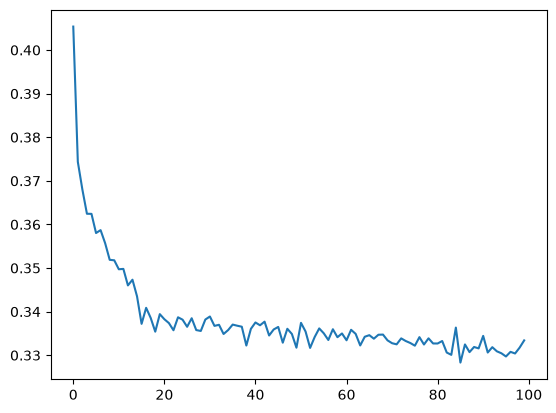

In [19]:
plt.plot(torch.tensor(lossi).view(-1, 1000).mean(1))

In [14]:
for layer in model.layers:
    layer.training = False

In [21]:
# evaluate the loss
@torch.no_grad() # this decorator disables gradient tracking inside pytorch
def split_loss(split):
  x,y = {
    'train': (Xtr, Ytr),
    'val': (Xdev, Ydev),
  }[split]
  logits = model(x)
  loss = F.cross_entropy(logits, y)
  print(split, loss.item())

split_loss('train')
split_loss('val')

train 2.125554084777832
val 2.1547465324401855


In [15]:
for _ in range(20):
    
    out = []
    context = [0] * block_size # initialize with all ...
    while True:
      # forward pass the neural net
      x = torch.tensor([context])
      logits = model(x)
      probs = F.softmax(logits, dim=1)
      # sample from the distribution
      ix = torch.multinomial(probs, num_samples=1).item()
      # shift the context window and track the samples
      context = context[1:] + [ix]
      out.append(ix)
      # if we sample the special '.' token, break
      if ix == 0:
        break
    
    print(''.join(itos[i] for i in out)) # decode and print the generated word
    


yary.
loha.
ashyah.
essan.
keynnn.
cara.
dayuan.
elica.
ssihta.
leilani.
kanio.
chuunn.
stinian.
silwi.
amarji.
laisen.
haicay.
curistelki.
osannia.
apulcis.
